<a href="https://colab.research.google.com/github/Lagnajit09/100x_AI_ML/blob/main/TrainACalibratedModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **[1] — Install**

In [ ]:
!pip install -q -U "transformers>=4.48" datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 115.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 47.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 19.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


## **[2] — Imports and GPU check**

In [ ]:
import os, json, math, random, time, pickle
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import transformers
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| torch", torch.__version__, "| transformers", transformers.__version__)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU found: Runtime > Change runtime type > T4 GPU")

device: cuda | torch 2.11.0+cu130 | transformers 5.19.0
GPU: Tesla T4


## **[3] — Google Drive**

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## **[4] — Settings**

In [ ]:
SMOKE = True     # True: tiny practice run (a few minutes). False: the real experiment.

MODEL_NAME   = "answerdotai/ModernBERT-base"
DATASET_NAME = "m-lagnajit/calibrated-typed-decisions"
OUT_DIR = "/content/drive/MyDrive/ctd_student_smoke" if SMOKE else "/content/drive/MyDrive/ctd_student"
os.makedirs(OUT_DIR, exist_ok=True)

RUNS = ["A", "B", "C"]          # A: right answers only, B: softened evenly, C: teacher's soft labels
SEED = 0

# Step 2: building the input
MAX_LEN        = 512            # longest sequence the student reads
MAX_Q_TOKENS   = 64             # cap on the question
MAX_OPT_TOKENS = 24             # cap on each option, so options can never crowd out the text

# Step 6: training
BATCH_SIZE   = 16
EPOCHS       = 1 if SMOKE else 3
LR_BODY      = 3e-5             # small, careful steps for the pre-trained body
LR_HEAD      = 1e-3             # bigger steps for the brand-new scorer
WEIGHT_DECAY = 0.01
WARMUP_FRAC  = 0.10
CLIP_NORM    = 1.0
SMOOTHING    = 0.1              # Run B: how much belief to spread evenly
USE_AMP      = True             # 16-bit math on the GPU; set False if the loss turns NaN
SAVE_WEIGHTS = not SMOKE        # save each run's best student to Drive (~600 MB each)

# Step 7: evaluation
N_BINS       = 10
N_BOOT       = 1000
MIN_FIT_ROWS = 30
SMOKE_SIZES  = {"train": 160, "validation": 80, "test": 80}

def amp_on():
    return USE_AMP and device == "cuda"

## **[5] — Load your dataset**

In [ ]:
ds = load_dataset(DATASET_NAME)
print(ds)

def take(split):
    rows = list(ds[split])
    if SMOKE:
        rows = random.Random(SEED).sample(rows, min(SMOKE_SIZES[split], len(rows)))
    return rows

DATA = {split: take(split) for split in ["train", "validation", "test"]}
print({split: len(rows) for split, rows in DATA.items()})
print(pd.DataFrame(DATA["train"]).groupby(["source", "type"]).size())

r = DATA["train"][0]
print(json.dumps({k: r[k] for k in ["source", "type", "instructions", "state",
                                    "options", "gold", "teacher_probs"]}, indent=2)[:1200])

README.md:   0%|          | 0.00/6.92k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.30MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  408kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/4998 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1500 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1499 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'source', 'source_license', 'type', 'instructions', 'state', 'options', 'gold', 'gold_index', 'display_perm', 'teacher_option_logprobs', 'teacher_temperature', 'teacher_shift', 'teacher_probs', 'teacher_letter_mass'],
        num_rows: 4998
    })
    validation: Dataset({
        features: ['id', 'source', 'source_license', 'type', 'instructions', 'state', 'options', 'gold', 'gold_index', 'display_perm', 'teacher_option_logprobs', 'teacher_temperature', 'teacher_shift', 'teacher_probs', 'teacher_letter_mass'],
        num_rows: 1500
    })
    test: Dataset({
        features: ['id', 'source', 'source_license', 'type', 'instructions', 'state', 'options', 'gold', 'gold_index', 'display_perm', 'teacher_option_logprobs', 'teacher_temperature', 'teacher_shift', 'teacher_probs', 'teacher_letter_mass'],
        num_rows: 1499
    })
})
{'train': 160, 'validation': 80, 'test': 80}
source                                type  
clinc/c

## **[6] — Tokenizer and special tokens**

In [ ]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
CLS, SEP, MASK, PAD = tok.cls_token_id, tok.sep_token_id, tok.mask_token_id, tok.pad_token_id
print({"[CLS]": CLS, "[SEP]": SEP, "[MASK]": MASK, "[PAD]": PAD})
assert None not in (CLS, SEP, MASK, PAD), "tokenizer is missing a special token"

config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/20.8k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.13M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

{'[CLS]': 50281, '[SEP]': 50282, '[MASK]': 50284, '[PAD]': 50283}


## **[7] — Tokenize every piece once**

In [ ]:
def option_texts(row):
    """The words the student sees for each option, in stored order."""
    return ["no", "yes"] if row["type"] == "noul" else row["options"]

def pretokenize(rows):
    qs   = tok([r["instructions"] for r in rows], add_special_tokens=False)["input_ids"]
    txts = tok([" " + r["state"] for r in rows], add_special_tokens=False)["input_ids"]
    flat = [" " + o for r in rows for o in option_texts(r)]
    flat_ids = tok(flat, add_special_tokens=False)["input_ids"]
    k = 0
    for r, q, t in zip(rows, qs, txts):
        n = len(option_texts(r))
        r["q_ids"]   = q[:MAX_Q_TOKENS]
        r["opt_ids"] = [o[:MAX_OPT_TOKENS] for o in flat_ids[k:k + n]]
        r["txt_ids"] = t
        k += n

for split in DATA:
    pretokenize(DATA[split])

r = DATA["train"][0]
print("question pieces:", tok.convert_ids_to_tokens(r["q_ids"]))
print("option pieces:  ", [tok.convert_ids_to_tokens(o) for o in r["opt_ids"]])

question pieces: ['Which', 'Ġintent', 'Ġbest', 'Ġdescribes', 'Ġthis', 'Ġrequest', 'Ġto', 'Ġa', 'Ġvoice', 'Ġassistant', '?']
option pieces:   [['Ġweather', 'Ġquery'], ['Ġsocial', 'Ġpost'], ['Ġq', 'a', 'Ġstock'], ['Ġaudio', 'Ġvolume', 'Ġdown'], ['Ġtake', 'away', 'Ġquery'], ['Ġtake', 'away', 'Ġorder']]


## **[8] — Build one input sequence**

In [ ]:
def build_input(row, rng=None):
    """[CLS] question [SEP] [MASK] opt [MASK] opt ... [SEP] text [SEP]
    rng=None -> options in stored order (evaluation)
    rng      -> options in a random order (training), so position can't become a shortcut"""
    n = len(row["opt_ids"])
    perm = list(range(n))
    if rng is not None:
        rng.shuffle(perm)                  # shown slot d holds stored option perm[d]
    ids = [CLS] + row["q_ids"] + [SEP]
    marker_pos = []
    for c in perm:
        marker_pos.append(len(ids))        # this option's [MASK] lands here
        ids += [MASK] + row["opt_ids"][c]
    ids += [SEP]
    room = MAX_LEN - len(ids) - 1          # leave space for the final [SEP]
    ids += row["txt_ids"][:room] + [SEP]   # only the text can ever be cut
    return {"input_ids": ids, "marker_pos": marker_pos, "perm": perm}

ex = build_input(DATA["train"][0])
print(len(ex["input_ids"]), "tokens | markers at", ex["marker_pos"])
for p, piece in enumerate(tok.convert_ids_to_tokens(ex["input_ids"])[:40]):
    print(f"{p:3d}  {piece}{'   <- marker' if p in ex['marker_pos'] else ''}")

41 tokens | markers at [13, 16, 19, 23, 27, 31]
  0  [CLS]
  1  Which
  2  Ġintent
  3  Ġbest
  4  Ġdescribes
  5  Ġthis
  6  Ġrequest
  7  Ġto
  8  Ġa
  9  Ġvoice
 10  Ġassistant
 11  ?
 12  [SEP]
 13  [MASK]   <- marker
 14  Ġweather
 15  Ġquery
 16  [MASK]   <- marker
 17  Ġsocial
 18  Ġpost
 19  [MASK]   <- marker
 20  Ġq
 21  a
 22  Ġstock
 23  [MASK]   <- marker
 24  Ġaudio
 25  Ġvolume
 26  Ġdown
 27  [MASK]   <- marker
 28  Ġtake
 29  away
 30  Ġquery
 31  [MASK]   <- marker
 32  Ġtake
 33  away
 34  Ġorder
 35  [SEP]
 36  Ġstock
 37  Ġrate
 38  Ġof
 39  Ġfacebook


## **[9] — Each run’s target**

In [ ]:
def make_target(row, run):
    """The run's target, in stored order."""
    n, g = len(row["opt_ids"]), row["gold_index"]
    if run == "A":                                   # 100% on the right answer
        t = np.zeros(n)
        t[g] = 1.0
    elif run == "B":                                 # 0.9 + 0.1/n on the right answer, 0.1/n elsewhere
        t = np.full(n, SMOOTHING / n)
        t[g] += 1.0 - SMOOTHING
    elif run == "C":                                 # the teacher's calibrated soft label
        t = np.array(row["teacher_probs"], dtype=float)
        t = t / t.sum()
    else:
        raise ValueError(run)
    return t

r = DATA["train"][0]
print("options:", option_texts(r), "| right answer:", r["gold"])
for run in RUNS:
    print(f"target {run}:", np.round(make_target(r, run), 3))

options: ['weather query', 'social post', 'qa stock', 'audio volume down', 'takeaway query', 'takeaway order'] | right answer: qa stock
target A: [0. 0. 1. 0. 0. 0.]
target B: [0.017 0.017 0.917 0.017 0.017 0.017]
target C: [0.002 0.002 0.984 0.002 0.005 0.005]


## **[10] — Build a batch**

In [ ]:
def make_batch(rows, run=None, rng=None):
    items = [build_input(r, rng) for r in rows]
    B = len(rows)
    L = max(len(it["input_ids"]) for it in items)       # longest sequence in this batch
    K = max(len(it["marker_pos"]) for it in items)      # most options in this batch
    input_ids   = torch.full((B, L), PAD, dtype=torch.long)
    attn        = torch.zeros((B, L), dtype=torch.long)
    marker_pos  = torch.zeros((B, K), dtype=torch.long) # empty slots point at position 0
    option_mask = torch.zeros((B, K), dtype=torch.bool)
    target      = torch.zeros((B, K), dtype=torch.float)
    perms = []
    for b, (row, it) in enumerate(zip(rows, items)):
        n_tok, k = len(it["input_ids"]), len(it["marker_pos"])
        input_ids[b, :n_tok] = torch.tensor(it["input_ids"])
        attn[b, :n_tok] = 1
        marker_pos[b, :k] = torch.tensor(it["marker_pos"])
        option_mask[b, :k] = True
        if run is not None:
            t = make_target(row, run)
            target[b, :k] = torch.tensor(t[it["perm"]], dtype=torch.float)   # into shown order
        perms.append(it["perm"])
    return {"input_ids": input_ids, "attention_mask": attn, "marker_pos": marker_pos,
            "option_mask": option_mask, "target": target, "perms": perms}

demo = make_batch(DATA["train"][:8], run="C", rng=random.Random(0))
for k, v in demo.items():
    if torch.is_tensor(v):
        print(f"{k:15s} shape {tuple(v.shape)}")
print("option_mask:\n", demo["option_mask"].int())

input_ids       shape (8, 69)
attention_mask  shape (8, 69)
marker_pos      shape (8, 7)
option_mask     shape (8, 7)
target          shape (8, 7)
option_mask:
 tensor([[1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1],
        [1, 1, 0, 0, 0, 0, 0],
        [1, 1, 0, 0, 0, 0, 0],
        [1, 1, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 0]], dtype=torch.int32)


## **[11] — The student**

In [ ]:
MODEL_INPUTS = ["input_ids", "attention_mask", "marker_pos", "option_mask"]

class Student(nn.Module):
    def __init__(self, name):
        super().__init__()
        try:
            self.body = AutoModel.from_pretrained(name, reference_compile=False)
        except (TypeError, ValueError):
            self.body = AutoModel.from_pretrained(name)
        self.body = self.body.float()
        self.scorer = nn.Linear(self.body.config.hidden_size, 1)        # 768 weights + 1 bias

    def forward(self, input_ids, attention_mask, marker_pos, option_mask):
        h = self.body(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state  # (B, L, 768)
        idx = marker_pos.unsqueeze(-1).expand(-1, -1, h.size(-1))                           # (B, K, 768)
        markers = torch.gather(h, 1, idx)                                                   # (B, K, 768)
        scores = self.scorer(markers).squeeze(-1)                                           # (B, K)
        return scores.masked_fill(~option_mask, float("-inf"))                              # block empty slots

torch.manual_seed(SEED)
_student = Student(MODEL_NAME)
print(f"body:   {sum(p.numel() for p in _student.body.parameters()):,} numbers")
print(f"scorer: {sum(p.numel() for p in _student.scorer.parameters()):,} numbers")
with torch.no_grad():
    s = _student(**{k: demo[k] for k in MODEL_INPUTS})
print("scores shape:", tuple(s.shape))
print("untrained chances, row 0:", torch.softmax(s[0], dim=-1).numpy().round(3))
del _student

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
decoder.bias      | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


body:   149,014,272 numbers
scorer: 769 numbers
scores shape: (8, 7)
untrained chances, row 0: [0.195 0.212 0.121 0.118 0.191 0.162 0.   ]


## **[12] — The loss**

In [ ]:
def soft_cross_entropy(scores, target, option_mask):
    log_p = torch.log_softmax(scores.float(), dim=-1)
    log_p = log_p.masked_fill(~option_mask, 0.0)        # empty slots count as 0, not 0 × (−∞)
    return -(target * log_p).sum(dim=-1).mean()

# Check against Step 5's worked example
s = torch.tensor([[0.12, 2.35, 1.06, 0.06]])
m = torch.ones(1, 4, dtype=torch.bool)
for run, t in [("A", [0, 1, 0, 0]), ("B", [0.025, 0.925, 0.025, 0.025]), ("C", [0.08, 0.68, 0.18, 0.06])]:
    print(run, round(soft_cross_entropy(s, torch.tensor([t], dtype=torch.float), m).item(), 3))

A 0.395
B 0.54
C 0.943


## **[13] — Predicting and measuring**

In [ ]:
@torch.no_grad()
def predict_scores(model, rows, bs=64):
    """Raw scores for every row, in stored order: one numpy array per row."""
    model.eval()
    out = []
    for i in range(0, len(rows), bs):
        batch = make_batch(rows[i:i + bs])                     # no rng: stored order
        feed = {k: batch[k].to(device) for k in MODEL_INPUTS}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_on()):
            s = model(**feed).float().cpu().numpy()
        for b, perm in enumerate(batch["perms"]):
            row_scores = np.empty(len(perm))
            row_scores[perm] = s[b, :len(perm)]                # shown order -> stored order
            out.append(row_scores)
    model.train()
    return out

def softmax_np(z):
    z = z - z.max()
    e = np.exp(z)
    return e / e.sum()

def per_row(probs_list, rows):
    """Confidence, right/wrong, and log-loss penalty for each question."""
    conf    = np.array([p.max() for p in probs_list])
    correct = np.array([float(p.argmax() == r["gold_index"]) for p, r in zip(probs_list, rows)])
    nll     = np.array([-np.log(max(p[r["gold_index"]], 1e-12)) for p, r in zip(probs_list, rows)])
    return conf, correct, nll

def ece_from(conf, correct, idx=None):
    if idx is not None:
        conf, correct = conf[idx], correct[idx]
    bins  = np.minimum((conf * N_BINS).astype(int), N_BINS - 1)
    said  = np.bincount(bins, weights=conf,    minlength=N_BINS)   # total confidence per group
    right = np.bincount(bins, weights=correct, minlength=N_BINS)   # total right answers per group
    return float(np.abs(right - said).sum() / len(conf))

def metrics(probs_list, rows):
    conf, correct, nll = per_row(probs_list, rows)
    return {"accuracy": correct.mean(), "ECE": ece_from(conf, correct), "log loss": nll.mean()}

## **[14] — One complete training run**

In [ ]:
def lr_factor(step, total, warmup):
    """Warmup to 1.0, then a straight fall to 0 (Step 6e)."""
    if step < warmup:
        return (step + 1) / warmup
    return max(0.0, (total - step) / max(1, total - warmup))

def make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)

def train_run(run):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    model = Student(MODEL_NAME).to(device)
    model.train()
    optimizer = torch.optim.AdamW([
        {"params": model.body.parameters(),   "lr": LR_BODY},
        {"params": model.scorer.parameters(), "lr": LR_HEAD},
    ], weight_decay=WEIGHT_DECAY)

    train = DATA["train"]
    steps_per_epoch = math.ceil(len(train) / BATCH_SIZE)
    total  = steps_per_epoch * EPOCHS
    warmup = max(1, int(WARMUP_FRAC * total))
    schedule = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: lr_factor(s, total, warmup))
    scaler = make_scaler(amp_on())
    print(f"run {run}: {len(train)} questions, {steps_per_epoch} steps per epoch, "
          f"{total} steps in total, warmup {warmup}")

    best, history, step = {"val_loss": float("inf")}, [], 0
    for epoch in range(EPOCHS):
        rng = random.Random(SEED * 1000 + epoch)           # same shuffle and swaps in every run
        order = list(range(len(train)))
        rng.shuffle(order)
        t0, losses = time.time(), []
        for i in range(0, len(order), BATCH_SIZE):
            batch = make_batch([train[j] for j in order[i:i + BATCH_SIZE]], run=run, rng=rng)
            feed = {k: batch[k].to(device) for k in MODEL_INPUTS}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_on()):
                scores = model(**feed)                                          # Steps 2-4: guess
            loss = soft_cross_entropy(scores, batch["target"].to(device), feed["option_mask"])  # Step 5
            if not torch.isfinite(loss):
                raise RuntimeError("Loss became NaN or infinite. Set USE_AMP = False in Cell 4, "
                                   "rerun from Cell 4, and train again.")
            scaler.scale(loss).backward()                                       # slopes
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM)       # safety belt
            scaler.step(optimizer)                                              # nudge downhill
            scaler.update()
            schedule.step()
            optimizer.zero_grad(set_to_none=True)
            losses.append(loss.item())
            step += 1
            if step % 50 == 0:
                print(f"  epoch {epoch + 1} | step {step}/{total} | train loss {np.mean(losses[-50:]):.4f} "
                      f"| body lr {schedule.get_last_lr()[0]:.1e}")

        # Validation check: real answers, the same scoring for every run (Step 6g)
        val = metrics([softmax_np(s) for s in predict_scores(model, DATA["validation"])], DATA["validation"])
        history.append({"epoch": epoch + 1, "train_loss": float(np.mean(losses)),
                        "val_loss": float(val["log loss"]), "val_accuracy": float(val["accuracy"]),
                        "val_ECE": float(val["ECE"])})
        print(f"run {run} | epoch {epoch + 1} done in {time.time() - t0:.0f}s | train loss {np.mean(losses):.4f} "
              f"| val loss {val['log loss']:.4f} | val acc {val['accuracy']:.3f} | val ECE {val['ECE']:.3f}")
        if val["log loss"] < best["val_loss"]:
            best = {"val_loss": val["log loss"], "epoch": epoch + 1,
                    "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
            print(f"  -> new best student (epoch {epoch + 1})")

    model.load_state_dict(best["state"])
    print(f"run {run}: keeping epoch {best['epoch']}")
    preds = {"run": run, "best_epoch": best["epoch"], "history": history,
             "validation": predict_scores(model, DATA["validation"]),
             "test": predict_scores(model, DATA["test"])}
    with open(f"{OUT_DIR}/preds_{run}.pkl", "wb") as f:
        pickle.dump(preds, f)
    if SAVE_WEIGHTS:
        torch.save(best["state"], f"{OUT_DIR}/student_{run}.pt")
    del model, optimizer, best
    torch.cuda.empty_cache()
    return preds

## **[15] — Train the three students**

In [ ]:
PREDS = {}
for run in RUNS:
    path = f"{OUT_DIR}/preds_{run}.pkl"
    if os.path.exists(path):
        with open(path, "rb") as f:
            PREDS[run] = pickle.load(f)
        print(f"run {run}: already trained, loaded from Drive (kept epoch {PREDS[run]['best_epoch']})")
    else:
        print(f"\n========== training run {run} ==========")
        PREDS[run] = train_run(run)


========== training run A ==========


Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
decoder.bias      | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


run A: 160 questions, 10 steps per epoch, 10 steps in total, warmup 1
run A | epoch 1 done in 6s | train loss 1.2162 | val loss 1.2175 | val acc 0.375 | val ECE 0.075
  -> new best student (epoch 1)
run A: keeping epoch 1

========== training run B ==========


Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
decoder.bias      | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


run B: 160 questions, 10 steps per epoch, 10 steps in total, warmup 1
run B | epoch 1 done in 3s | train loss 1.2163 | val loss 1.2067 | val acc 0.400 | val ECE 0.086
  -> new best student (epoch 1)
run B: keeping epoch 1

========== training run C ==========


Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
decoder.bias      | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


run C: 160 questions, 10 steps per epoch, 10 steps in total, warmup 1
run C | epoch 1 done in 3s | train loss 1.2388 | val loss 1.2111 | val acc 0.425 | val ECE 0.130
  -> new best student (epoch 1)
run C: keeping epoch 1


## **[16] — Give every student a dial**

In [ ]:
GRID   = np.exp(np.linspace(np.log(0.25), np.log(20.0), 200))   # dial settings to try
B_GRID = np.linspace(-8.0, 8.0, 321)                             # nudge sizes to try (yes/no only)

def probs_with_dial(scores, qtype, T, b):
    z = np.array(scores, dtype=float) / T
    if qtype == "noul":
        z[1] += b
    return softmax_np(z)

def fit_dial(scores, rows):
    """The (dial, nudge) with the lowest validation log loss. Nudge only for yes/no."""
    if rows[0]["type"] == "noul":
        gap = np.array([s[1] - s[0] for s in scores])
        y   = np.array([r["gold_index"] for r in rows])
        with np.errstate(over="ignore"):
            z = gap[None, None, :] / GRID[:, None, None] + B_GRID[None, :, None]
            p = 1.0 / (1.0 + np.exp(-z))
        pen = -(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)).mean(axis=2)
        i, j = np.unravel_index(np.argmin(pen), pen.shape)
        return float(GRID[i]), float(B_GRID[j])
    losses = [np.mean([-np.log(probs_with_dial(s, "choice", T, 0.0)[r["gold_index"]] + 1e-12)
                       for s, r in zip(scores, rows)]) for T in GRID]
    return float(GRID[int(np.argmin(losses))]), 0.0

def group_of(row):
    return (row["source"], row["type"])

def fit_dials(val_scores, val_rows):
    pooled = {}
    for qtype in ["choice", "noul"]:
        pairs = [(s, r) for s, r in zip(val_scores, val_rows) if r["type"] == qtype]
        pooled[qtype] = fit_dial(*zip(*pairs)) if len(pairs) >= MIN_FIT_ROWS else (1.0, 0.0)
    dials = {}
    for g in {group_of(r) for r in val_rows}:
        pairs = [(s, r) for s, r in zip(val_scores, val_rows) if group_of(r) == g]
        dials[g] = fit_dial(*zip(*pairs)) if len(pairs) >= MIN_FIT_ROWS else pooled[g[1]]
    return dials, pooled

def apply_dials(scores, rows, dials, pooled):
    return [probs_with_dial(s, r["type"], *dials.get(group_of(r), pooled[r["type"]]))
            for s, r in zip(scores, rows)]

TEST = DATA["test"]
PROBS = {}                          # name -> chances for every test question
for run in RUNS:
    dials, pooled = fit_dials(PREDS[run]["validation"], DATA["validation"])
    PROBS[f"Student {run}"]        = [softmax_np(s) for s in PREDS[run]["test"]]
    PROBS[f"Student {run} + dial"] = apply_dials(PREDS[run]["test"], TEST, dials, pooled)
    print(f"Student {run} dials:", {f"{g[0].split('/')[-1]}/{g[1]}": (round(T, 2), round(b, 2))
                                    for g, (T, b) in sorted(dials.items())})
PROBS["Teacher"] = [np.array(r["teacher_probs"]) / np.sum(r["teacher_probs"]) for r in TEST]

Student A dials: {'clinc_oos/choice': (1.0, 0.0), 'clinc_oos/noul': (1.0, 0.0), 'go_emotions/choice': (1.0, 0.0), 'go_emotions/noul': (1.0, 0.0), 'amazon_massive_intent/choice': (1.0, 0.0), 'amazon_massive_intent/noul': (1.0, 0.0), 'amazon_polarity/choice': (1.0, 0.0), 'amazon_polarity/noul': (1.0, 0.0), 'banking77/choice': (1.0, 0.0), 'banking77/noul': (1.0, 0.0)}
Student B dials: {'clinc_oos/choice': (0.92, 0.0), 'clinc_oos/noul': (1.0, 0.0), 'go_emotions/choice': (0.92, 0.0), 'go_emotions/noul': (1.0, 0.0), 'amazon_massive_intent/choice': (0.92, 0.0), 'amazon_massive_intent/noul': (1.0, 0.0), 'amazon_polarity/choice': (0.92, 0.0), 'amazon_polarity/noul': (1.0, 0.0), 'banking77/choice': (0.92, 0.0), 'banking77/noul': (1.0, 0.0)}
Student C dials: {'clinc_oos/choice': (0.94, 0.0), 'clinc_oos/noul': (1.0, 0.0), 'go_emotions/choice': (0.94, 0.0), 'go_emotions/noul': (1.0, 0.0), 'amazon_massive_intent/choice': (0.94, 0.0), 'amazon_massive_intent/noul': (1.0, 0.0), 'amazon_polarity/choice'

## **[17] — The results tables**

In [ ]:
LABELS = {"A": "right answers only", "B": "softened evenly", "C": "teacher's soft labels"}
rows_out = []
for run in RUNS:
    raw  = metrics(PROBS[f"Student {run}"], TEST)
    dial = metrics(PROBS[f"Student {run} + dial"], TEST)
    rows_out.append({"model": f"Student {run} ({LABELS[run]})", "kept epoch": PREDS[run]["best_epoch"],
                     "accuracy": raw["accuracy"], "ECE": raw["ECE"], "log loss": raw["log loss"],
                     "accuracy after dial": dial["accuracy"], "ECE after dial": dial["ECE"],
                     "log loss after dial": dial["log loss"]})
t = metrics(PROBS["Teacher"], TEST)
rows_out.append({"model": "Teacher (dial + nudge)", "accuracy": t["accuracy"],
                 "ECE": t["ECE"], "log loss": t["log loss"]})
results = pd.DataFrame(rows_out).round(3)
display(results)
results.to_csv(f"{OUT_DIR}/results_overall.csv", index=False)

breakdown = []
for g in sorted({group_of(r) for r in TEST}):
    idx  = [i for i, r in enumerate(TEST) if group_of(r) == g]
    sub  = [TEST[i] for i in idx]
    line = {"source": g[0].split("/")[-1], "type": g[1], "n": len(idx)}
    for name, short in [("Student A", "A"), ("Student B", "B"), ("Student C", "C"), ("Teacher", "teacher")]:
        m = metrics([PROBS[name][i] for i in idx], sub)
        line[f"acc {short}"] = m["accuracy"]
        line[f"ECE {short}"] = m["ECE"]
    breakdown.append(line)
breakdown = pd.DataFrame(breakdown).round(3)
display(breakdown)
breakdown.to_csv(f"{OUT_DIR}/results_by_source.csv", index=False)

,model,kept epoch,accuracy,ECE,log loss,accuracy after dial,ECE after dial,log loss after dial
0,Student A (right answers only),1.0,0.412,0.135,1.247,0.412,0.135,1.247
1,Student B (softened evenly),1.0,0.362,0.133,1.250,0.362,0.123,1.253
2,Student C (teacher's soft labels),1.0,0.425,0.071,1.223,0.425,0.085,1.224
3,Teacher (dial + nudge),NaN,0.875,0.044,0.372,NaN,NaN,NaN


,source,type,n,acc A,ECE A,acc B,ECE B,acc C,ECE C,acc teacher,ECE teacher
0,clinc_oos,choice,11,0.364,0.203,0.273,0.150,0.455,0.141,1.000,0.007
1,clinc_oos,noul,6,0.500,0.032,0.667,0.137,0.667,0.101,1.000,0.102
2,go_emotions,choice,9,0.444,0.302,0.444,0.296,0.333,0.165,0.556,0.184
3,go_emotions,noul,3,0.333,0.242,0.333,0.245,0.333,0.582,1.000,0.303
4,amazon_massive_intent,choice,16,0.375,0.138,0.250,0.084,0.375,0.204,0.938,0.081
5,amazon_massive_intent,noul,4,0.500,0.053,0.500,0.046,0.750,0.162,0.750,0.167
6,amazon_polarity,choice,11,0.455,0.195,0.364,0.326,0.455,0.335,1.000,0.052
7,amazon_polarity,noul,4,0.750,0.237,0.500,0.016,0.500,0.022,1.000,0.029
8,banking77,choice,11,0.364,0.295,0.364,0.214,0.273,0.183,0.909,0.096
9,banking77,noul,5,0.200,0.510,0.200,0.355,0.400,0.163,0.400,0.491


## **[18] — Real difference or luck?**

In [ ]:
N = len(TEST)
IDX = np.random.default_rng(SEED).integers(0, N, size=(N_BOOT, N))   # the same redraws for every model
ROW_STATS = {name: per_row(PROBS[name], TEST) for name in PROBS}

def boot(name, measure):
    conf, correct, nll = ROW_STATS[name]
    if measure == "ECE":
        return np.array([ece_from(conf, correct, idx) for idx in IDX])
    if measure == "log loss":
        return np.array([nll[idx].mean() for idx in IDX])
    return np.array([correct[idx].mean() for idx in IDX])          # accuracy

lines = []
for suffix in ["", " + dial"]:
    for measure, lower_is_better in [("accuracy", False), ("ECE", True), ("log loss", True)]:
        c = boot(f"Student C{suffix}", measure)
        for other in ["A", "B"]:
            o = boot(f"Student {other}{suffix}", measure)
            diff = (o - c) if lower_is_better else (c - o)          # positive = C better
            lo, hi = np.percentile(diff, [2.5, 97.5])
            lines.append({"comparison": f"C vs {other}{suffix}", "measure": measure,
                          "C better in": f"{int((diff > 0).sum())}/{N_BOOT}",
                          "average gap": round(float(diff.mean()), 4),
                          "95% range": f"[{lo:+.4f}, {hi:+.4f}]",
                          "verdict": "C better" if lo > 0 else ("C worse" if hi < 0 else "too close to call")})
boot_df = pd.DataFrame(lines)
display(boot_df)
boot_df.to_csv(f"{OUT_DIR}/bootstrap.csv", index=False)

,comparison,measure,C better in,average gap,95% range,verdict
0,C vs A,accuracy,545/1000,0.0128,"[-0.0875, +0.1250]",too close to call
1,C vs B,accuracy,878/1000,0.0621,"[-0.0253, +0.1500]",too close to call
2,C vs A,ECE,759/1000,0.0342,"[-0.0662, +0.1299]",too close to call
3,C vs B,ECE,746/1000,0.0357,"[-0.0718, +0.1377]",too close to call
4,C vs A,log loss,864/1000,0.0241,"[-0.0168, +0.0660]",too close to call
5,C vs B,log loss,903/1000,0.0269,"[-0.0141, +0.0672]",too close to call
6,C vs A + dial,accuracy,545/1000,0.0128,"[-0.0875, +0.1250]",too close to call
7,C vs B + dial,accuracy,878/1000,0.0621,"[-0.0253, +0.1500]",too close to call
8,C vs A + dial,ECE,704/1000,0.0275,"[-0.0761, +0.1267]",too close to call
9,C vs B + dial,ECE,624/1000,0.0187,"[-0.0895, +0.1242]",too close to call


## **[19] — Reliability diagrams**

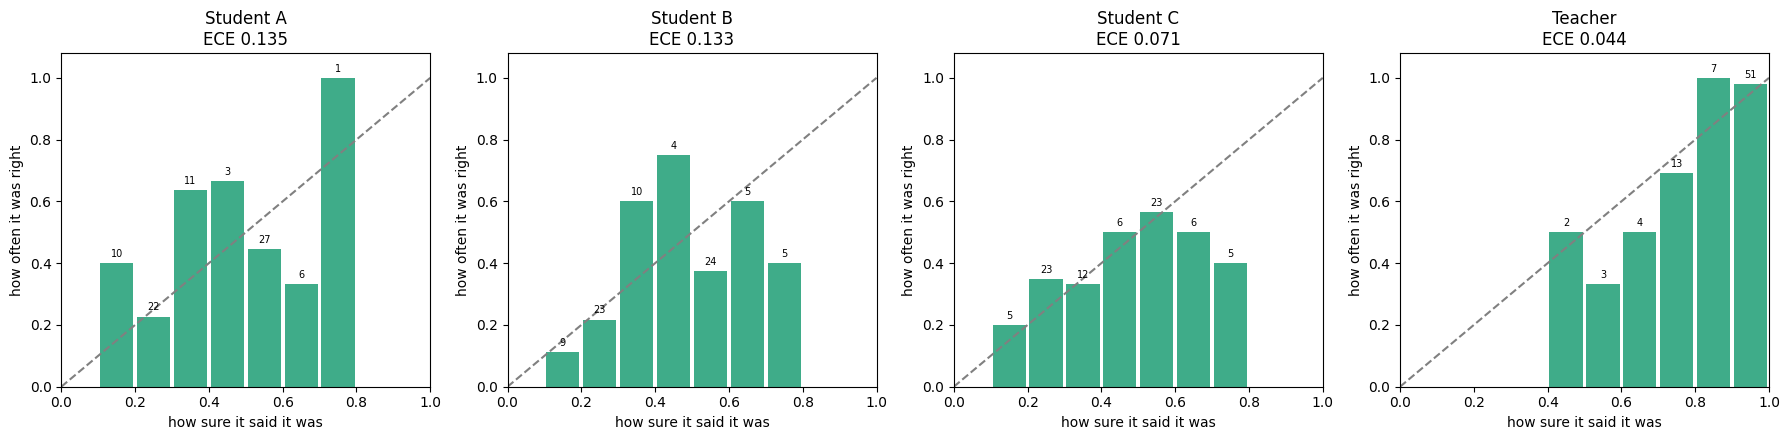

In [ ]:
def reliability(ax, probs, rows, title):
    conf, correct, _ = per_row(probs, rows)
    bins = np.minimum((conf * N_BINS).astype(int), N_BINS - 1)
    for b in range(N_BINS):
        m = bins == b
        if m.any():
            center = (b + 0.5) / N_BINS
            ax.bar(center, correct[m].mean(), width=0.9 / N_BINS, color="#1D9E75", alpha=0.85)
            ax.text(center, correct[m].mean() + 0.02, str(int(m.sum())), ha="center", fontsize=7)
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set(xlim=(0, 1), ylim=(0, 1.08), xlabel="how sure it said it was", ylabel="how often it was right",
           title=f"{title}\nECE {ece_from(conf, correct):.3f}")

panels = ["Student A", "Student B", "Student C", "Teacher"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, name in zip(axes, panels):
    reliability(ax, PROBS[name], TEST, name)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/reliability.png", dpi=150)
plt.show()

## **[20] — Training curves**

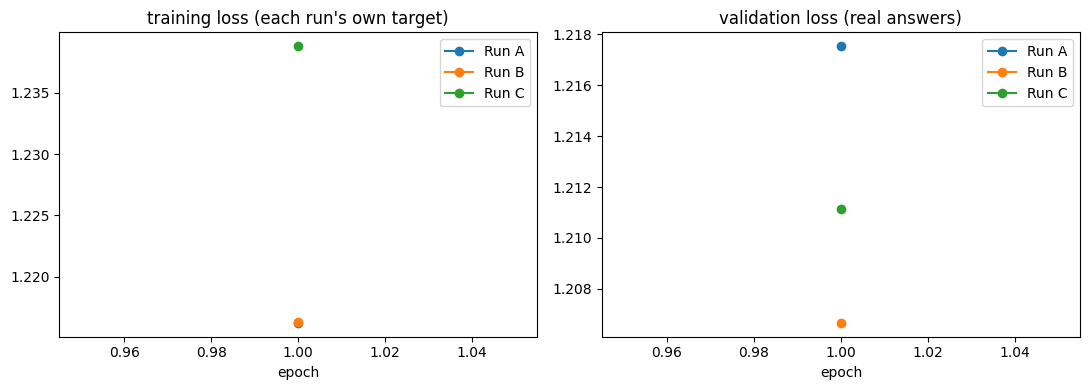

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for run in RUNS:
    h = pd.DataFrame(PREDS[run]["history"])
    axes[0].plot(h["epoch"], h["train_loss"], marker="o", label=f"Run {run}")
    axes[1].plot(h["epoch"], h["val_loss"],   marker="o", label=f"Run {run}")
axes[0].set(title="training loss (each run's own target)", xlabel="epoch")
axes[1].set(title="validation loss (real answers)", xlabel="epoch")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/training_curves.png", dpi=150)
plt.show()

## **[21] — (Optional): install Laya**

In [ ]:
!pip install -q laya

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.0/113.0 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 380.5/380.5 kB 14.9 MB/s eta 0:00:00


## **[22] — (Optional): Laya as an outside reference**

In [ ]:
from laya import Router
router = Router()

def laya_chances(row):
    if row["type"] == "noul":
        q = {"d": {"type": "noul", "instructions": row["instructions"]}}
    else:
        q = {"d": {"type": "choice", "instructions": row["instructions"],
                   "criteria": {o: o for o in row["options"]}}}
    ans = router.predict(row["state"], q)["answers"]["d"]
    if row["type"] == "noul":
        p_true = ans.get("probability", ans.get("value"))
        if p_true is None:
            raise KeyError(f"Couldn't find the yes/no probability in Laya's answer: {ans}")
        return np.array([1.0 - float(p_true), float(p_true)])
    p = np.array([float(ans["probabilities"].get(o, 0.0)) for o in row["options"]])
    if p.sum() == 0:
        raise KeyError(f"Laya's option names didn't match: {ans}")
    return p / p.sum()

t0 = time.time()
PROBS["Laya"] = [laya_chances(r) for r in TEST]
print(f"Laya scored {len(TEST)} test questions in {time.time() - t0:.0f}s")
print({k: round(float(v), 3) for k, v in metrics(PROBS["Laya"], TEST).items()})